# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнил студент гр. 3383 Канцеров Артемий Николаевич. Вариант №13.

Официальные материалы: [условие практической работы](https://se.moevm.pro/doku.php/courses:digital_signal_processing:prac1), [таблица вариантов](https://se.moevm.pro/doku.php/courses:digital_signal_processing:prac1:prac1-vars).


## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.


## Основные теоретические положения

### Линейная дискретная система

Передаточная функция рекурсивного звена второго порядка имеет вид

$$
H(z)=\frac{Y(z)}{X(z)}=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{a_0+a_1z^{-1}+a_2z^{-2}}.
$$

При $a_0=1$ соответствующее разностное уравнение записывается как

$$
y[n]=\sum_{i=0}^{2}b_i x[n-i]-\sum_{k=1}^{2}a_k y[n-k].
$$

Нулевые начальные условия означают, что $x[n]=0$ и $y[n]=0$ при $n<0$. Импульсная характеристика $h[n]$ является реакцией системы на единичный импульс $\delta[n]$. Для рекурсивного звена

$$
h[n]=b_0\delta[n]+b_1\delta[n-1]+b_2\delta[n-2]-a_1h[n-1]-a_2h[n-2].
$$

Реакция линейной стационарной системы на произвольное воздействие определяется линейной свёрткой

$$
y[n]=(x*h)[n]=\sum_{m=-\infty}^{\infty}x[m]h[n-m].
$$

Для конечных последовательностей длины $N_x$ и $N_h$ длина полной свёртки равна $N_x+N_h-1$.

Нули являются корнями числителя $b_0z^2+b_1z+b_2$, а полюсы — корнями знаменателя $a_0z^2+a_1z+a_2$. Причинная рациональная система устойчива, если все полюсы лежат строго внутри единичной окружности.

Частотная характеристика получается на единичной окружности $z=e^{j\omega}$:

$$
H(e^{j\omega})=\frac{\sum_{i=0}^{2}b_i e^{-j\omega i}}{\sum_{k=0}^{2}a_k e^{-j\omega k}},\qquad
A(\omega)=|H(e^{j\omega})|,\qquad
\varphi(\omega)=\arg H(e^{j\omega}).
$$

Нормированная угловая частота определяется как $\hat{\omega}=\omega/\pi$; ей соответствует абсолютная частота $f=\hat{\omega}f_d/2$.


### Дискретное преобразование Фурье

Для последовательности длины $N$ прямое и обратное ДПФ задаются формулами

$$
X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N},\qquad
x[n]=\frac{1}{N}\sum_{k=0}^{N-1}X[k]e^{j2\pi kn/N}.
$$

Дискретному индексу $k$ соответствуют частоты $f_k=kf_d/N$ и $\hat{\omega}_k=2k/N$ после перехода к симметричной шкале. Для двустороннего амплитудного спектра периодической последовательности используется величина $|X[k]|/N$. Поэтому каждая косинусоидальная составляющая амплитуды $A$ образует две симметричные спектральные линии высотой $A/2$.

Равенство Парсеваля связывает энергию во временной и частотной областях:

$$
\sum_{n=0}^{N-1}|x[n]|^2=\frac{1}{N}\sum_{k=0}^{N-1}|X[k]|^2.
$$


## Постановка задачи

Требуется программно исследовать рекурсивную дискретную систему второго порядка: вычислить импульсную характеристику, реакции по свёртке и разностному уравнению, нули и полюсы, карту нулей и полюсов, АЧХ и ФЧХ в нормированной и абсолютной шкалах. Затем требуется сформировать периодическую последовательность из двух гармоник, проверить ДПФ и ОДПФ, построить амплитудный и фазовый спектры, сопоставить ДПФ конечной и периодической последовательностей, восстановить аналоговый сигнал и проверить равенство Парсеваля.

### Исходные данные варианта 13

Для первой части:

$$
\begin{aligned}
b_0&=0.76, & b_1&=0.922336, & b_2&=1.064,\\
a_0&=1, & a_1&=-1.1028, & a_2&=0.718,\\
N_1&=23, & N_2&=33, & f_d&=13000\ \text{Hz}.
\end{aligned}
$$

Для второй части:

$$
N=64,\quad f_d=8000\ \text{Hz},\quad T=1.25\cdot10^{-4}\ \text{s},\quad
A_1=1.13,\quad A_2=2.26,\quad f_1=1000\ \text{Hz},\quad f_2=1500\ \text{Hz}.
$$

Число единичных отсчётов прямоугольного импульса определяется округлением $N_2/2=16.5$ до ближайшего большего целого, то есть равно 17. Такой выбор исключает банковское округление функции **round()** языка R.


## Выполнение работы

### Подготовка вычислительной среды и параметров

Используются только функции базовой поставки R. Это устраняет внешние зависимости и обеспечивает воспроизводимость.


In [1]:
locale_candidates <- c("Russian_Russia.65001", "ru_RU.UTF-8", "Russian_Russia.1251")
for (locale_candidate in locale_candidates) {
  locale_result <- suppressWarnings(Sys.setlocale("LC_CTYPE", locale_candidate))
  if (!is.na(locale_result)) break
}
options(encoding = "UTF-8", repr.plot.width = 9, repr.plot.height = 5, digits = 8)

variant <- 13

# Часть 1
b <- c(
  0.5 + 0.02 * variant,
  (0.5 + 0.02 * variant) * (-1)^(variant + 1) * (0.9822 + 0.0178 * variant),
  (0.5 + 0.02 * variant) * (0.8 + 0.2 * (variant %% 5))
)
a <- c(1, (-1)^variant * (0.7778 + 0.025 * variant), 0.64 + 0.006 * variant)
N1 <- variant %% 10 + 20
N2 <- variant %% 10 + 30
fd1 <- 1000 * variant

# Часть 2
N <- 64
fd2 <- 2000 * (variant %% 5 + 1)
T <- 1 / fd2
A1 <- 1 + 0.01 * variant
A2 <- 2 * A1
f1 <- fd2 / 8
f2 <- 1.5 * f1

parameters <- data.frame(
  parameter = c("b0", "b1", "b2", "a0", "a1", "a2", "N1", "N2", "fd_1", "N", "fd_2", "T", "A1", "A2", "f1", "f2"),
  value = c(b, a, N1, N2, fd1, N, fd2, T, A1, A2, f1, f2)
)
parameters

stopifnot(
  isTRUE(all.equal(b, c(0.76, 0.922336, 1.064), tolerance = 1e-12)),
  isTRUE(all.equal(a, c(1, -1.1028, 0.718), tolerance = 1e-12)),
  N1 == 23, N2 == 33, fd1 == 13000,
  N == 64, fd2 == 8000,
  isTRUE(all.equal(c(A1, A2, f1, f2), c(1.13, 2.26, 1000, 1500), tolerance = 1e-12))
)


Your code contains a unicode char which cannot be displayed in your
current locale and R will silently convert it to an escaped form when the
R kernel executes this code. This can lead to subtle errors if you use
such chars to do comparisons. For more information, please see
https://github.com/IRkernel/repr/wiki/Problems-with-unicode-on-windows

parameter,value
<chr>,<dbl>
b0,0.760000
b1,0.922336
b2,1.064000
a0,1.000000
a1,-1.102800
a2,0.718000
N1,23.000000
N2,33.000000
fd_1,13000.000000


### Часть 1. Импульсная характеристика

Импульсная характеристика вычисляется непосредственным применением разностного уравнения при $x[n]=\delta[n]$ и нулевых начальных условиях. Значение $N_1=23$ задаёт только длину наблюдаемого фрагмента. Поскольку система рекурсивная и её полюсы ненулевые, истинная импульсная характеристика имеет бесконечную длину и асимптотически стремится к нулю при устойчивости системы.

Для комплексно-сопряжённых полюсов $p_{1,2}=re^{\pm j\varphi}$ вводится последовательность

$$
g[n]=r^n\frac{\sin((n+1)\varphi)}{\sin\varphi}u[n],
$$

где $u[n]$ обозначает единичную ступенчатую последовательность. Аналитическая формула импульсной характеристики:

$$
h[n]=b_0g[n]+b_1g[n-1]+b_2g[n-2].
$$

Для варианта 13 $r=\sqrt{0.718}\approx0.847349$, $\varphi\approx0.862244\approx0.274461\pi$, поэтому

$$
h[n]=0.76g[n]+0.922336g[n-1]+1.064g[n-2].
$$


n,h_difference,h_analytic,absolute_error
<int>,<dbl>,<dbl>,<dbl>
0,0.760000000,0.760000000,0.0000000e+00
1,1.760464000,1.760464000,0.0000000e+00
2,2.459759699,2.459759699,0.0000000e+00
3,1.448609844,1.448609844,4.4408921e-16
4,-0.168580528,-0.168580528,4.4408921e-16
5,-1.226012474,-1.226012474,2.2204460e-16
6,-1.231005738,-1.231005738,2.2204460e-16
7,-0.477276171,-0.477276171,3.8857806e-16
8,0.357521958,0.357521958,5.5511151e-17


r = 0.847348807; phi = 0.862243563 rad = 0.274460650*pi; max error = 4.441e-16


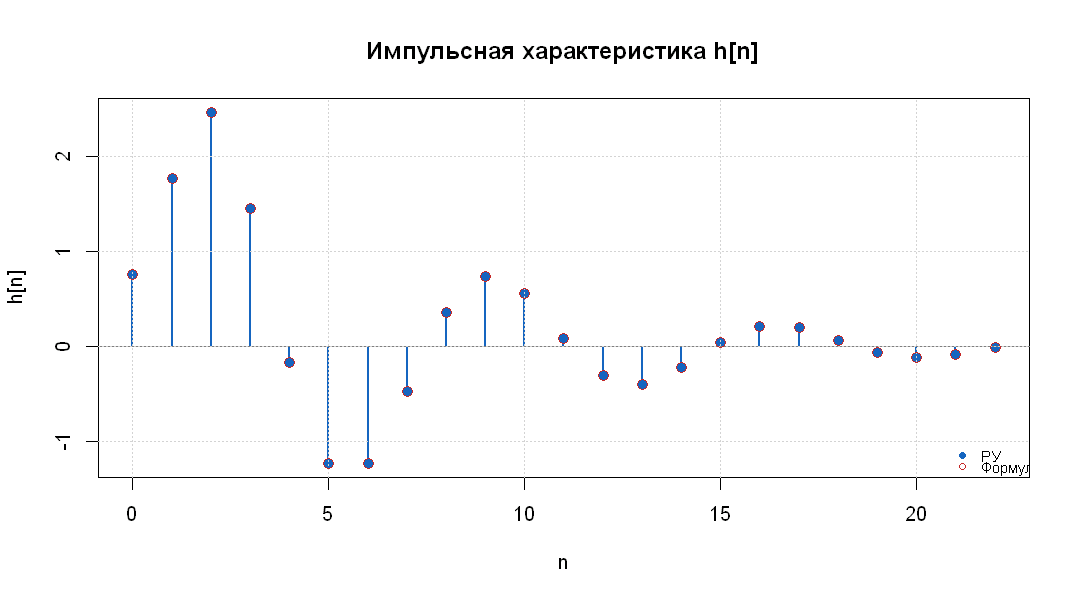

In [2]:
difference_response <- function(x, b, a) {
  stopifnot(a[1] != 0)
  y <- numeric(length(x))
  for (n in 0:(length(x) - 1)) {
    feedforward <- 0
    for (i in 0:(length(b) - 1)) {
      if (n - i >= 0) feedforward <- feedforward + b[i + 1] * x[n - i + 1]
    }
    feedback <- 0
    if (length(a) > 1) {
      for (k in 1:(length(a) - 1)) {
        if (n - k >= 0) feedback <- feedback + a[k + 1] * y[n - k + 1]
      }
    }
    y[n + 1] <- (feedforward - feedback) / a[1]
  }
  y
}

stem_plot <- function(n, x, main, xlab = "n", ylab = "Значение", col = "#1565C0") {
  plot(n, x, type = "h", lwd = 2, col = col, main = main, xlab = xlab, ylab = ylab)
  points(n, x, pch = 16, col = col)
  abline(h = 0, col = "grey50")
  grid()
}

delta <- c(1, rep(0, N1 - 1))
h <- difference_response(delta, b, a)
r_p <- sqrt(a[3])
phi_p <- acos(-a[2] / (2 * r_p))
g <- function(m) {
  ifelse(m >= 0, r_p^m * sin((m + 1) * phi_p) / sin(phi_p), 0)
}
n_h <- 0:(N1 - 1)
h_analytic <- b[1] * g(n_h) + b[2] * g(n_h - 1) + b[3] * g(n_h - 2)
analytic_error <- max(abs(h - h_analytic))

stem_plot(n_h, h, "Импульсная характеристика h[n]", ylab = "h[n]")
points(n_h, h_analytic, pch = 1, cex = 1.2, col = "#C62828")
legend("bottomright", legend = c("РУ", "Формула"),
       col = c("#1565C0", "#C62828"), pch = c(16, 1), cex = 0.75, bty = "n")
data.frame(n = n_h, h_difference = h, h_analytic = h_analytic,
           absolute_error = abs(h - h_analytic))
cat(sprintf("r = %.9f; phi = %.9f rad = %.9f*pi; max error = %.3e
",
            r_p, phi_p, phi_p / pi, analytic_error))
stopifnot(analytic_error < 1e-12)


### Часть 1. Реакция по формуле свёртки

Воздействие длины 33 содержит 17 единичных и 16 нулевых отсчётов. Полная свёртка воздействия длины $N_2=33$ и сохранённого фрагмента импульсной характеристики длины $N_1=23$ содержит $33+23-1=55$ отсчётов. Для сопоставления с реакцией разностного уравнения отображаются первые 33 отсчёта, соответствующие длительности воздействия.


metric,value
<chr>,<dbl>
Длина x,33
Число единичных отсчётов,17
Длина полной свёртки,55
Длина ненулевой части,39
Длина ограниченной реакции,33


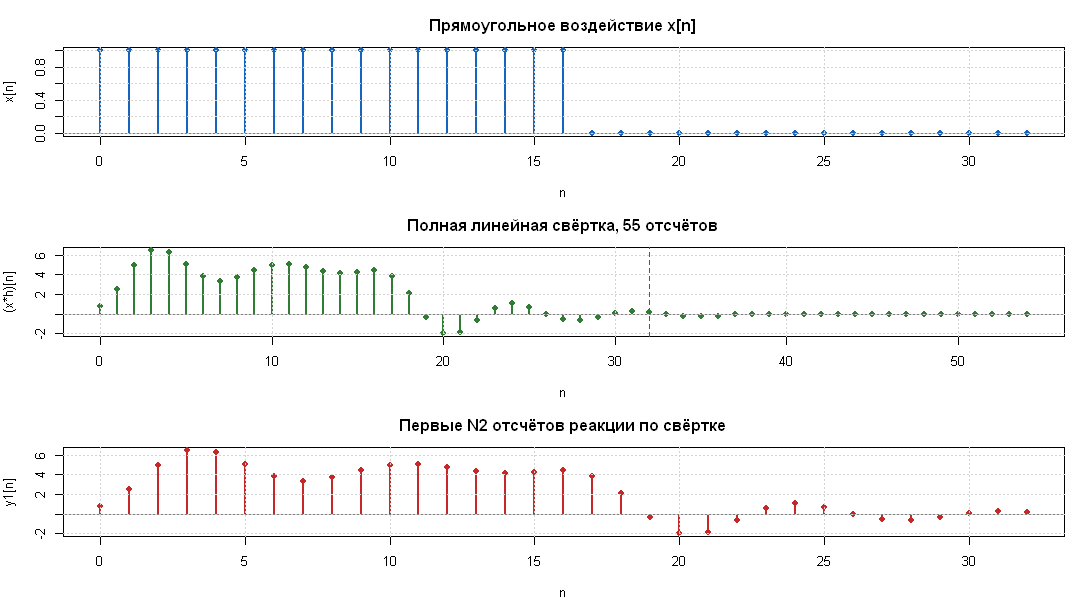

In [3]:
linear_convolution <- function(x, h) {
  y <- numeric(length(x) + length(h) - 1)
  for (n in 0:(length(y) - 1)) {
    for (m in 0:(length(x) - 1)) {
      h_index <- n - m
      if (h_index >= 0 && h_index < length(h)) {
        y[n + 1] <- y[n + 1] + x[m + 1] * h[h_index + 1]
      }
    }
  }
  y
}

pulse_length <- floor(N2 / 2 + 0.5)
x1 <- c(rep(1, pulse_length), rep(0, N2 - pulse_length))
y1_full <- linear_convolution(x1, h)
y1 <- y1_full[1:N2]

stopifnot(pulse_length == 17, length(y1_full) == 55, length(y1) == N2)

par(mfrow = c(3, 1), mar = c(4, 4, 3, 1))
stem_plot(0:(N2 - 1), x1, "Прямоугольное воздействие x[n]", ylab = "x[n]")
stem_plot(0:(length(y1_full) - 1), y1_full, "Полная линейная свёртка, 55 отсчётов",
          ylab = "(x*h)[n]", col = "#2E7D32")
abline(v = N2 - 1, lty = 2, col = "#C62828")
stem_plot(0:(N2 - 1), y1, "Первые N2 отсчётов реакции по свёртке", ylab = "y1[n]", col = "#C62828")
par(mfrow = c(1, 1))

nonzero_convolution_length <- pulse_length + N1 - 1
data.frame(metric = c("Длина x", "Число единичных отсчётов", "Длина полной свёртки",
                      "Длина ненулевой части", "Длина ограниченной реакции"),
           value = c(length(x1), sum(x1 == 1), length(y1_full),
                     nonzero_convolution_length, length(y1)))
stopifnot(nonzero_convolution_length == 39,
          all(abs(y1_full[(nonzero_convolution_length + 1):length(y1_full)]) < 1e-14))


### Часть 1. Реакция по разностному уравнению

Для варианта 13 разностное уравнение имеет вид

$$
y[n]=0.76x[n]+0.922336x[n-1]+1.064x[n-2]+1.1028y[n-1]-0.718y[n-2].
$$

Реакция $y_2[n]$ вычисляется на 33 отсчётах. Реакции $y_1[n]$ и $y_2[n]$ должны совпадать до отсчёта $n=N_1-1$. После него свёртка с усечённым фрагментом $h[n]$ уже не учитывает хвост истинной импульсной характеристики, поэтому появляется малая разность. Это не является ошибкой разностного уравнения.


metric,value
<chr>,<dbl>
"Максимальная ошибка на n=0,...,22",1.3322676e-15
"Максимальная ошибка на n=0,...,32",1.5012444e-01


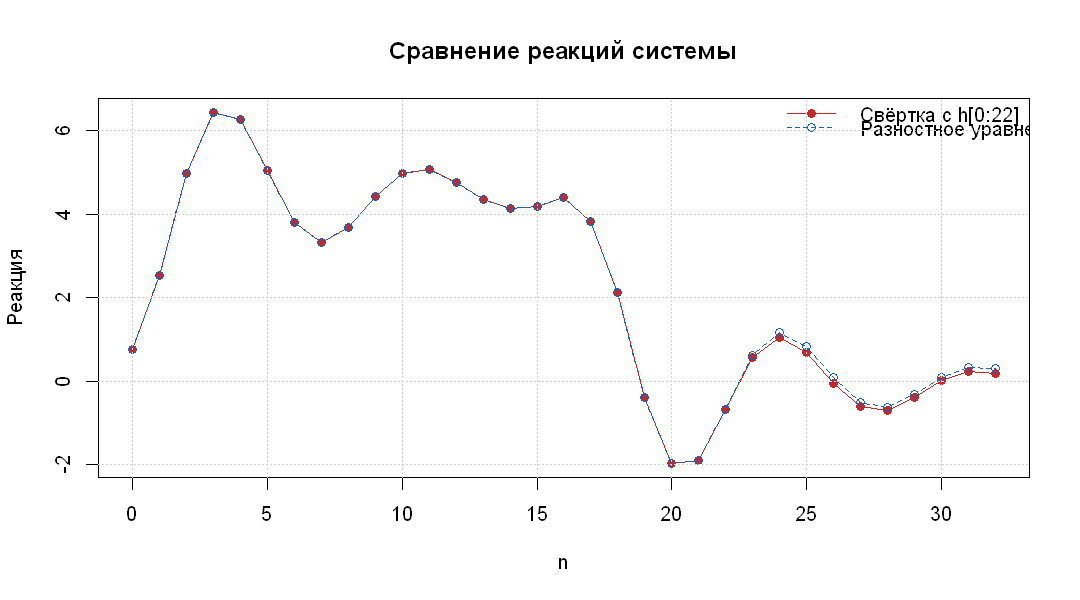

In [4]:
y2 <- difference_response(x1, b, a)
comparison <- data.frame(n = 0:(N2 - 1), y_convolution = y1, y_difference = y2, difference = y1 - y2)

matplot(0:(N2 - 1), cbind(y1, y2), type = "o", pch = c(16, 1), lty = c(1, 2),
        col = c("#C62828", "#1565C0"), xlab = "n", ylab = "Реакция",
        main = "Сравнение реакций системы")
legend("topright", legend = c("Свёртка с h[0:22]", "Разностное уравнение"),
       col = c("#C62828", "#1565C0"), lty = c(1, 2), pch = c(16, 1), bty = "n")
grid()

check_region_error <- max(abs(y1[1:N1] - y2[1:N1]))
full_region_error <- max(abs(y1 - y2))
data.frame(metric = c("Максимальная ошибка на n=0,...,22", "Максимальная ошибка на n=0,...,32"),
           value = c(check_region_error, full_region_error))
stopifnot(check_region_error < 1e-12)


### Часть 1. Нули, полюсы и устойчивость

Корни вычисляются в плоскости $z$, поэтому в функцию **polyroot()** передаются коэффициенты полиномов $b_0z^2+b_1z+b_2$ и $a_0z^2+a_1z+a_2$ в порядке возрастания степеней.

Ожидаемые пары комплексно-сопряжённых корней:

$$
z_{0}= -0.6068\pm j1.0157725=1.183216e^{\pm j0.671406\pi},
$$

$$
p_{0}= 0.5514\pm j0.6433957=0.847349e^{\pm j0.274461\pi}.
$$

Передаточная функция в виде произведения простейших множителей:

$$
H(z)=0.76\,
\frac{\left(1-1.183216e^{j0.671406\pi}z^{-1}\right)
      \left(1-1.183216e^{-j0.671406\pi}z^{-1}\right)}
     {\left(1-0.847349e^{j0.274461\pi}z^{-1}\right)
      \left(1-0.847349e^{-j0.274461\pi}z^{-1}\right)}.
$$

Модули полюсов меньше единицы, следовательно, система устойчива. Нули расположены вне единичной окружности; устойчивость определяется полюсами, а не нулями.


In [5]:
zeros <- polyroot(rev(b))
poles <- polyroot(rev(a))

root_table <- function(z, type) {
  data.frame(type = type, real = Re(z), imaginary = Im(z), modulus = Mod(z),
             argument_rad = Arg(z), argument_over_pi = Arg(z) / pi)
}
roots <- rbind(root_table(zeros, "Нуль"), root_table(poles, "Полюс"))
roots

cat(sprintf("H(z) = %.6f * [(1 - z0_1 z^-1)(1 - z0_2 z^-1)] / [(1 - p1 z^-1)(1 - p2 z^-1)]
", b[1]))
cat(sprintf("z0 = %.6f exp(±j %.6f*pi)
", Mod(zeros[1]), abs(Arg(zeros[1]) / pi)))
cat(sprintf("p  = %.6f exp(±j %.6f*pi)
", Mod(poles[1]), abs(Arg(poles[1]) / pi)))
stopifnot(all(Mod(poles) < 1))


type,real,imaginary,modulus,argument_rad,argument_over_pi
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Нуль,-0.6068,1.01577249,1.18321596,2.10928555,0.67140644
Нуль,-0.6068,-1.01577249,1.18321596,-2.10928555,-0.67140644
Полюс,0.5514,0.64339571,0.84734881,0.86224356,0.27446065
Полюс,0.5514,-0.64339571,0.84734881,-0.86224356,-0.27446065


H(z) = 0.760000 * [(1 - z0_1 z^-1)(1 - z0_2 z^-1)] / [(1 - p1 z^-1)(1 - p2 z^-1)]


z0 = 1.183216 exp(±j 0.671406*pi)


p  = 0.847349 exp(±j 0.274461*pi)


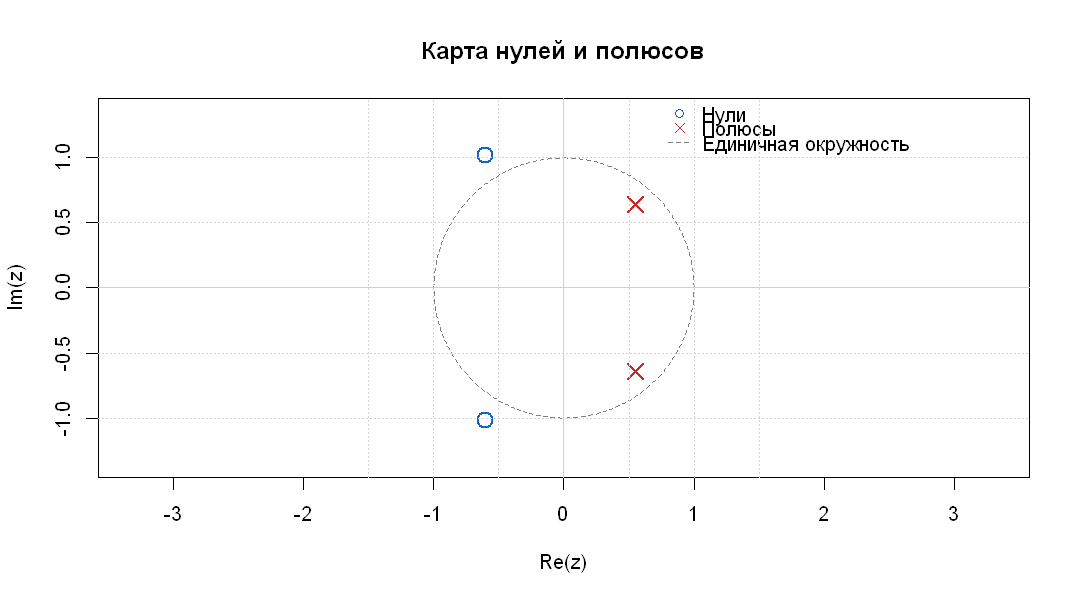

In [6]:
theta <- seq(0, 2 * pi, length.out = 600)
plot(cos(theta), sin(theta), type = "l", asp = 1, lty = 2, col = "grey50",
     xlab = "Re(z)", ylab = "Im(z)", main = "Карта нулей и полюсов",
     xlim = range(c(-1.35, 1.35, Re(zeros), Re(poles))),
     ylim = range(c(-1.35, 1.35, Im(zeros), Im(poles))))
abline(h = 0, v = 0, col = "grey80")
points(Re(zeros), Im(zeros), pch = 1, cex = 1.8, lwd = 2, col = "#1565C0")
points(Re(poles), Im(poles), pch = 4, cex = 1.8, lwd = 2, col = "#C62828")
legend("topright", legend = c("Нули", "Полюсы", "Единичная окружность"),
       pch = c(1, 4, NA), lty = c(NA, NA, 2), col = c("#1565C0", "#C62828", "grey50"), bty = "n")
grid()


### Часть 1. АЧХ и ФЧХ

Основная полоса нормированной частоты равна $-1\leq\hat{\omega}\leq1$, что соответствует $-6500\leq f\leq6500$ Гц при $f_d=13000$ Гц. Пики АЧХ тяготеют к углам полюсов, а ослабление — к углам нулей. Скачок фазы на $\pi$ при переходе через отрицательную вещественную полуось связан с выбором главного значения аргумента и обычно наблюдается там, где модуль характеристики мал.


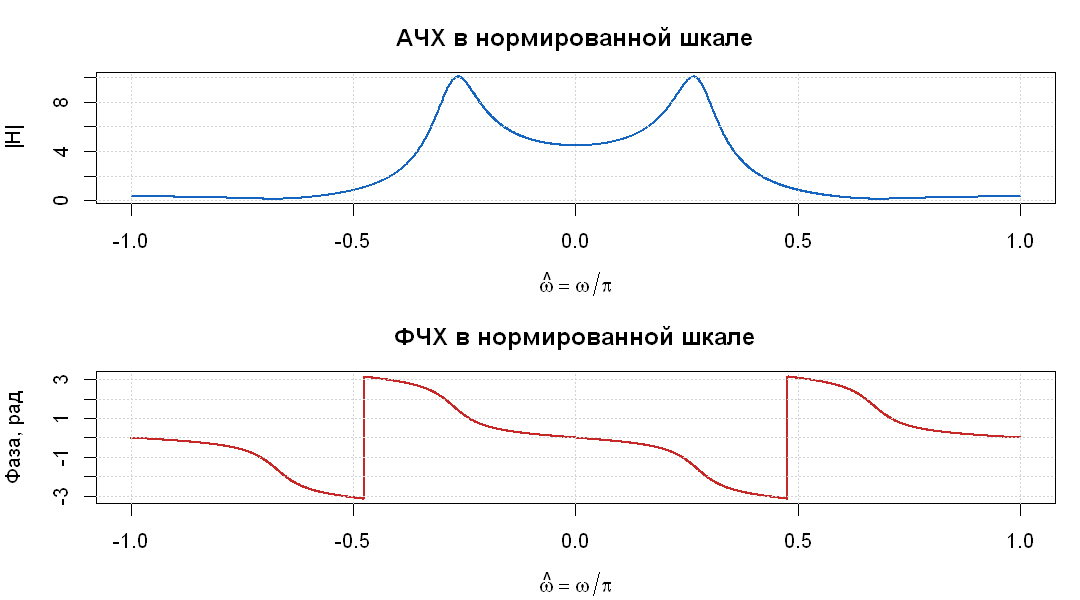

In [7]:
omega <- seq(-pi, pi, length.out = 2001)
frequency_response <- function(omega, b, a) {
  vapply(omega, function(w) {
    numerator <- sum(b * exp(-1i * w * 0:(length(b) - 1)))
    denominator <- sum(a * exp(-1i * w * 0:(length(a) - 1)))
    numerator / denominator
  }, complex(1))
}

H <- frequency_response(omega, b, a)
omega_hat <- omega / pi

par(mfrow = c(2, 1), mar = c(4, 4, 3, 1))
plot(omega_hat, Mod(H), type = "l", lwd = 2, col = "#1565C0",
     xlab = expression(hat(omega) == omega/pi), ylab = "|H|", main = "АЧХ в нормированной шкале")
grid()
plot(omega_hat, Arg(H), type = "l", lwd = 2, col = "#C62828",
     xlab = expression(hat(omega) == omega/pi), ylab = "Фаза, рад", main = "ФЧХ в нормированной шкале")
grid()
par(mfrow = c(1, 1))


characteristic,value,frequency_hz
<chr>,<dbl>,<dbl>
Минимум АЧХ,0.12883893,-4426.5
Максимум АЧХ,10.03955180,-1722.5


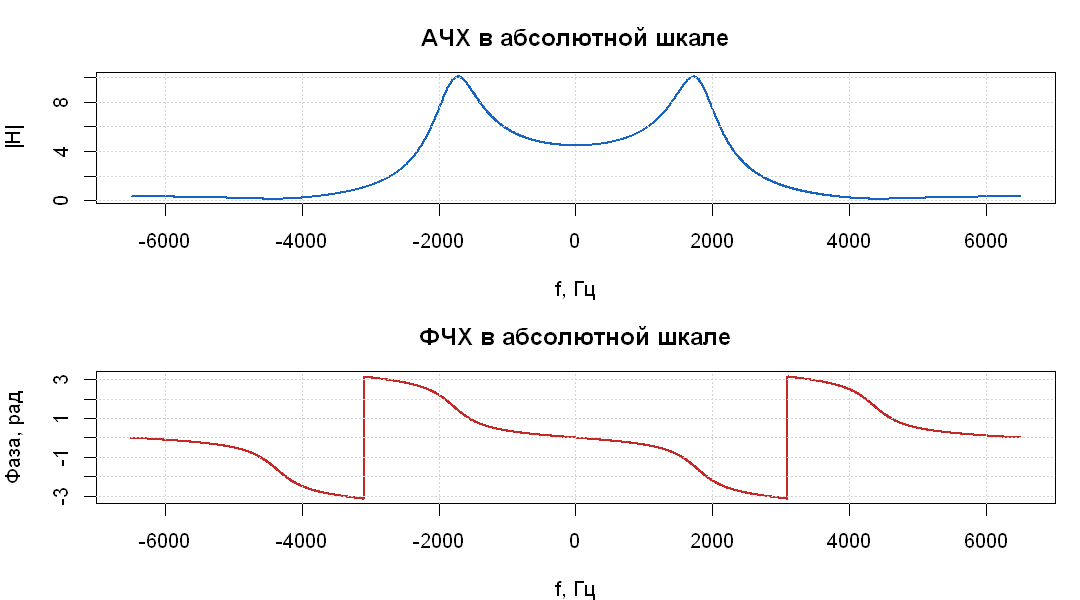

In [8]:
frequency_hz <- omega * fd1 / (2 * pi)
par(mfrow = c(2, 1), mar = c(4, 4, 3, 1))
plot(frequency_hz, Mod(H), type = "l", lwd = 2, col = "#1565C0",
     xlab = "f, Гц", ylab = "|H|", main = "АЧХ в абсолютной шкале")
grid()
plot(frequency_hz, Arg(H), type = "l", lwd = 2, col = "#C62828",
     xlab = "f, Гц", ylab = "Фаза, рад", main = "ФЧХ в абсолютной шкале")
grid()
par(mfrow = c(1, 1))

extrema <- data.frame(
  characteristic = c("Минимум АЧХ", "Максимум АЧХ"),
  value = c(min(Mod(H)), max(Mod(H))),
  frequency_hz = c(frequency_hz[which.min(Mod(H))], frequency_hz[which.max(Mod(H))])
)
extrema


Прямоугольный импульс содержит преимущественно низкочастотные составляющие. Для рассчитанной системы $|H(0)|\approx4.464$, а $|H(\pi)|\approx0.320$. Максимум АЧХ около 10.04 наблюдается вблизи $|f|=1722.5$ Гц, а минимум около 0.129 — вблизи $|f|=4426.5$ Гц. Следовательно, высокочастотные составляющие воздействия подавляются заметно сильнее низкочастотных, тогда как область около аргументов полюсов усиливается.


### Часть 2. Формирование периодической последовательности

Дискретное время равно $t_n=nT$, а нормированное дискретное время $t_n/T=n$. На периоде из 64 отсчётов первая гармоника укладывается 8 раз, вторая — 12 раз, поэтому спектральной утечки не возникает.


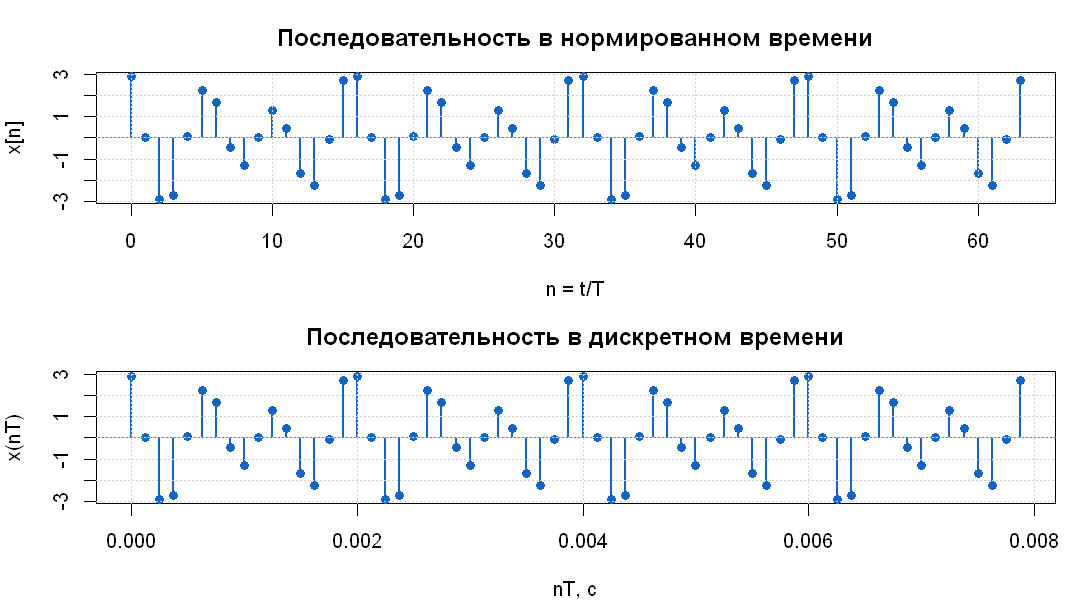

In [9]:
n <- 0:(N - 1)
t_n <- n * T
x2 <- A1 * cos(2 * pi * f1 * t_n + pi / 4) +
      A2 * cos(2 * pi * f2 * t_n + pi / 8)

par(mfrow = c(2, 1), mar = c(4, 4, 3, 1))
stem_plot(n, x2, "Последовательность в нормированном времени", xlab = "n = t/T", ylab = "x[n]")
stem_plot(t_n, x2, "Последовательность в дискретном времени", xlab = "nT, с", ylab = "x(nT)")
par(mfrow = c(1, 1))


### Часть 2. ДПФ и обратное ДПФ

Функция **fft()** вычисляет ДПФ без нормирующего множителя. Для ОДПФ используется выражение **fft(X, inverse=TRUE)/N**. Максимальная ошибка восстановления должна находиться на уровне машинного округления.


metric,value
<chr>,<dbl>
Максимальная абсолютная ошибка ОДПФ,1.7763568e-15


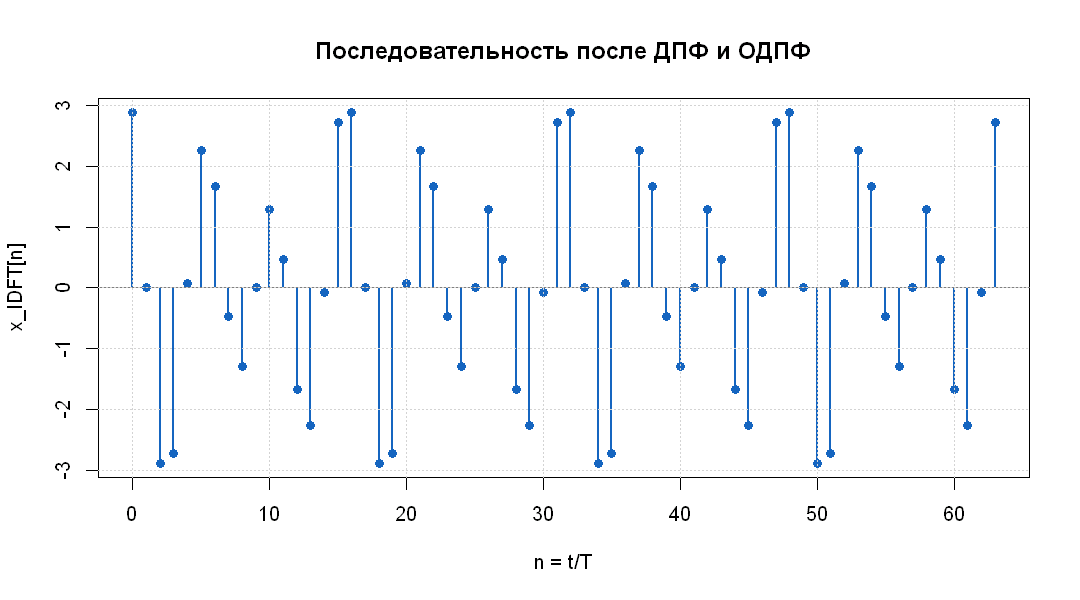

In [10]:
X <- fft(x2)
x_inverse <- Re(fft(X, inverse = TRUE) / N)
inverse_error <- max(abs(x2 - x_inverse))

stem_plot(n, x_inverse, "Последовательность после ДПФ и ОДПФ", xlab = "n = t/T", ylab = "x_IDFT[n]")
data.frame(metric = "Максимальная абсолютная ошибка ОДПФ", value = inverse_error)
stopifnot(inverse_error < 1e-12)


### Часть 2. Амплитудный и фазовый спектры

Используется двусторонняя симметричная шкала $k=-N/2,\ldots,N/2-1$. Абсолютные частоты равны $f_k=kf_d/N$, а нормированные — $\hat{\omega}_k=2k/N$. Ненулевые линии ожидаются при $\pm1000$ и $\pm1500$ Гц. Для исключения неоднозначности одновременно выводятся модуль ДПФ $|X[k]|$, коэффициенты ряда Фурье $|C[k]|=|X[k]|/N$ и амплитуды косинусоид $2|X[k]|/N$. Фаза для численно нулевых линий не имеет физического смысла и не отображается.


frequency_hz,normalized_frequency,dft_magnitude,fourier_coefficient,cosine_amplitude,phase_rad
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
-1500,-0.375,72.32,1.130,2.26,-0.39269908
-1000,-0.250,36.16,0.565,1.13,-0.78539816
1000,0.250,36.16,0.565,1.13,0.78539816
1500,0.375,72.32,1.130,2.26,0.39269908


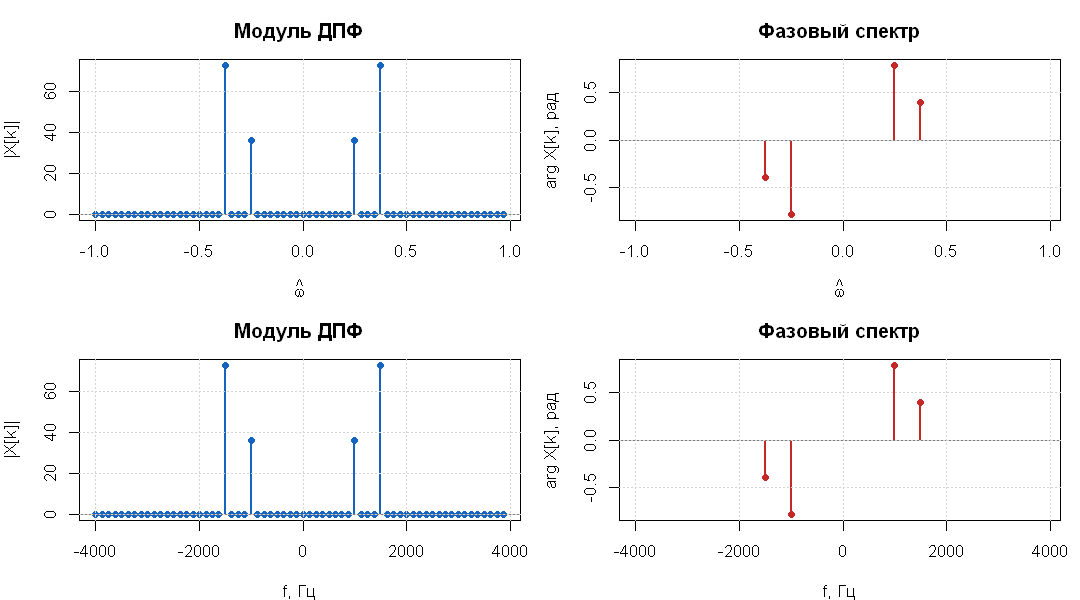

In [11]:
k_shift <- (-N / 2):(N / 2 - 1)
index_shift <- (k_shift %% N) + 1
X_shift <- X[index_shift]
f_shift <- k_shift * fd2 / N
omega_hat_shift <- 2 * k_shift / N
dft_magnitude <- Mod(X_shift)
fourier_coeff_amplitude <- dft_magnitude / N
phase_spectrum <- Arg(X_shift)
phase_spectrum[dft_magnitude < 1e-10] <- NA

par(mfrow = c(2, 2), mar = c(4, 4, 3, 1))
stem_plot(omega_hat_shift, dft_magnitude, "Модуль ДПФ", xlab = expression(hat(omega)), ylab = "|X[k]|")
stem_plot(omega_hat_shift, phase_spectrum, "Фазовый спектр", xlab = expression(hat(omega)), ylab = "arg X[k], рад", col = "#C62828")
stem_plot(f_shift, dft_magnitude, "Модуль ДПФ", xlab = "f, Гц", ylab = "|X[k]|")
stem_plot(f_shift, phase_spectrum, "Фазовый спектр", xlab = "f, Гц", ylab = "arg X[k], рад", col = "#C62828")
par(mfrow = c(1, 1))

significant <- dft_magnitude > 1e-10
spectral_lines <- data.frame(frequency_hz = f_shift[significant],
                             normalized_frequency = omega_hat_shift[significant],
                             dft_magnitude = dft_magnitude[significant],
                             fourier_coefficient = fourier_coeff_amplitude[significant],
                             cosine_amplitude = 2 * fourier_coeff_amplitude[significant],
                             phase_rad = phase_spectrum[significant])
spectral_lines
stopifnot(all(sort(round(spectral_lines$frequency_hz)) == c(-1500, -1000, 1000, 1500)))


### Часть 2. Конечная и периодическая последовательности

Один и тот же набор $N$ отсчётов можно трактовать как конечную последовательность или как один период периодической последовательности. Численные отсчёты ДПФ и их модули совпадают. При переходе к коэффициентам ряда Фурье периодического сигнала выполняется $|C[k]|=|X[k]|/N$. Поэтому отдельно проверяются совпадение модулей и нормированная связь.


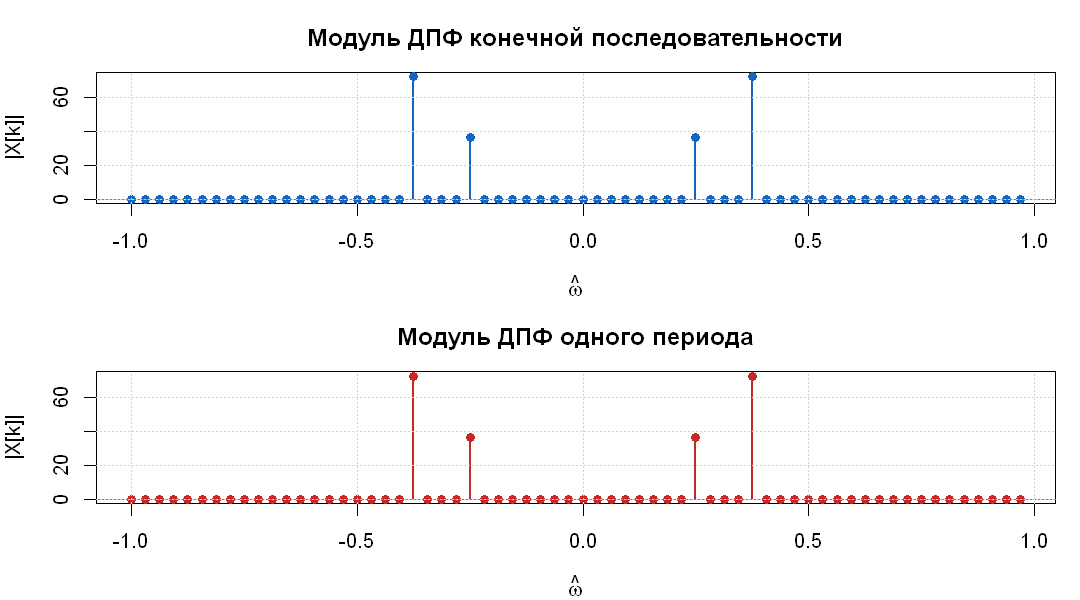

In [12]:
par(mfrow = c(2, 1), mar = c(4, 4, 3, 1))
stem_plot(omega_hat_shift, Mod(X_shift), "Модуль ДПФ конечной последовательности", xlab = expression(hat(omega)), ylab = "|X[k]|")
stem_plot(omega_hat_shift, dft_magnitude, "Модуль ДПФ одного периода", xlab = expression(hat(omega)), ylab = "|X[k]|", col = "#C62828")
par(mfrow = c(1, 1))
stopifnot(max(abs(Mod(X_shift) - dft_magnitude)) < 1e-14,
          max(abs(Mod(X_shift) / N - fourier_coeff_amplitude)) < 1e-14)


### Часть 2. Восстановление аналогового сигнала

Восстановление выполняется по всем $N$ спектральным отсчётам на интервале $0\leq t\leq(N-1)T$ с шагом $0.25T$:

$$
x_r(t)=\frac{1}{N}\sum_{k=-N/2}^{N/2-1}X_a[k]\exp\left(j\frac{2\pi}{NT}kt\right).
$$

Поскольку обе частоты точно совпадают с узлами сетки ДПФ и лежат ниже частоты Найквиста, восстановленный и исходный аналитический сигналы должны совпасть с точностью машинного округления.


metric,value
<chr>,<dbl>
Максимальная ошибка восстановления,4.6608550e-14
Максимальная мнимая невязка,1.4718205e-15


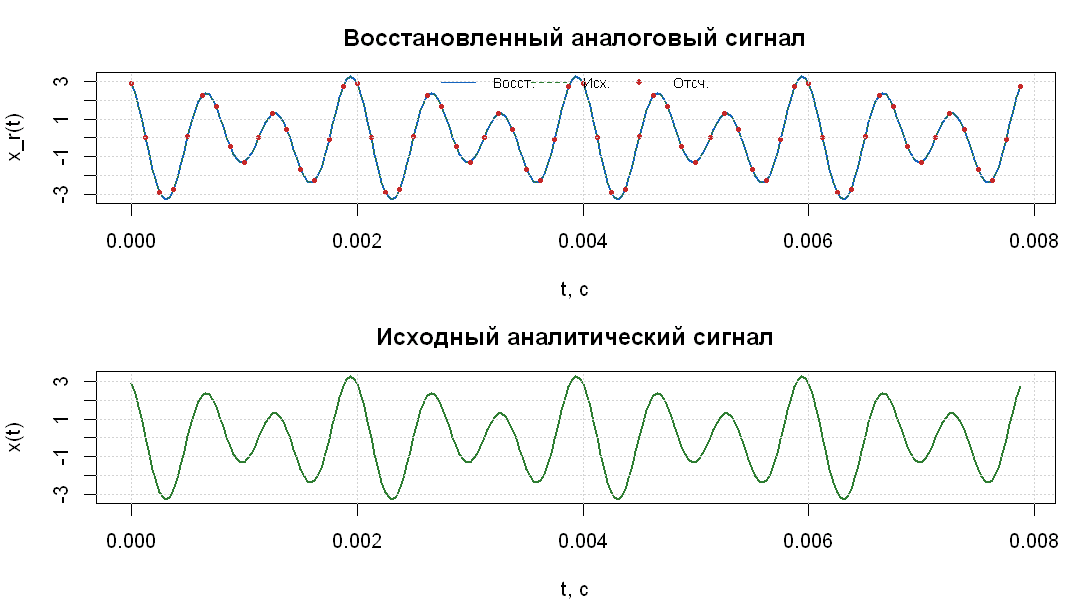

In [13]:
t_fine <- seq(0, (N - 1) * T, by = 0.25 * T)
x_reconstructed_complex <- vapply(t_fine, function(tt) {
  sum(X_shift * exp(1i * 2 * pi * k_shift * tt / (N * T))) / N
}, complex(1))
x_reconstructed <- Re(x_reconstructed_complex)
x_original <- A1 * cos(2 * pi * f1 * t_fine + pi / 4) +
              A2 * cos(2 * pi * f2 * t_fine + pi / 8)
reconstruction_error <- max(abs(x_reconstructed - x_original))
imaginary_residual <- max(abs(Im(x_reconstructed_complex)))

par(mfrow = c(2, 1), mar = c(4, 4, 3, 1))
plot(t_fine, x_reconstructed, type = "l", lwd = 2, col = "#1565C0",
     xlab = "t, с", ylab = "x_r(t)", main = "Восстановленный аналоговый сигнал")
lines(t_fine, x_original, lwd = 1.5, lty = 2, col = "#2E7D32")
points(t_n, x2, pch = 16, cex = 0.6, col = "#C62828")
legend("top", inset = 0.01, legend = c("Восст.", "Исх.", "Отсч."), horiz = TRUE,
       col = c("#1565C0", "#2E7D32", "#C62828"), lty = c(1, 2, NA),
       pch = c(NA, NA, 16), cex = 0.72, bty = "n")
grid()
plot(t_fine, x_original, type = "l", lwd = 2, col = "#2E7D32",
     xlab = "t, с", ylab = "x(t)", main = "Исходный аналитический сигнал")
grid()
par(mfrow = c(1, 1))

data.frame(metric = c("Максимальная ошибка восстановления", "Максимальная мнимая невязка"),
           value = c(reconstruction_error, imaginary_residual))
stopifnot(reconstruction_error < 1e-11, imaginary_residual < 1e-11)


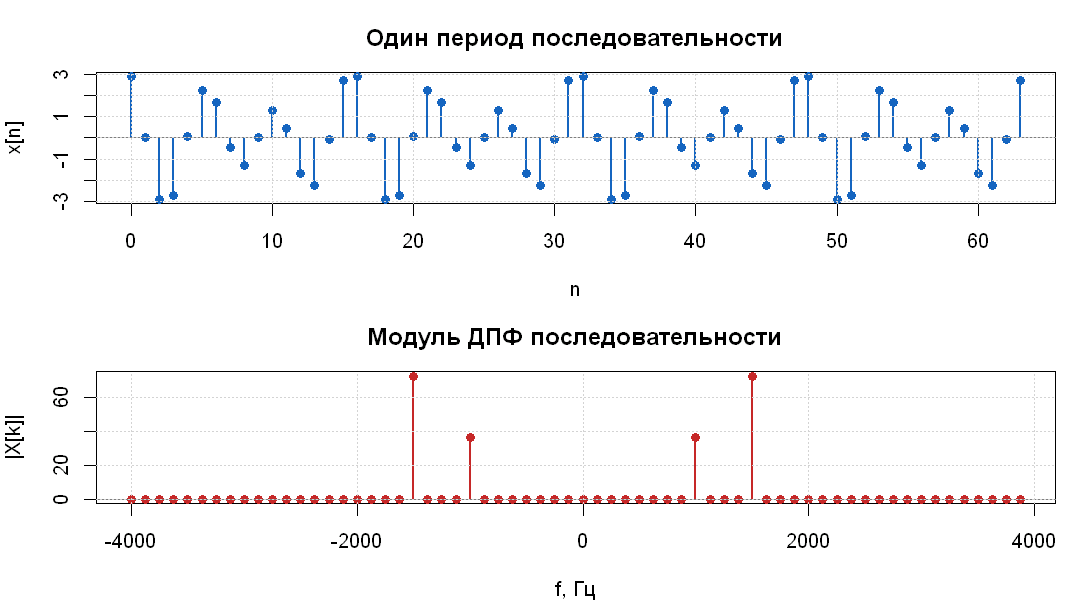

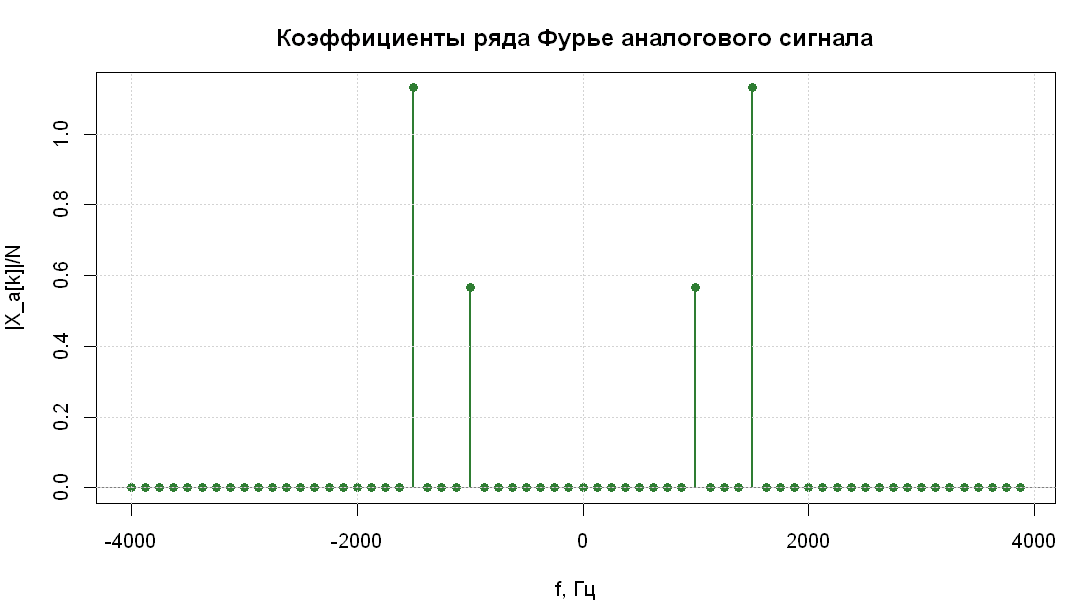

In [14]:
par(mfrow = c(2, 1), mar = c(4, 4, 3, 1))
stem_plot(n, x2, "Один период последовательности", xlab = "n", ylab = "x[n]")
stem_plot(f_shift, Mod(X_shift), "Модуль ДПФ последовательности", xlab = "f, Гц", ylab = "|X[k]|", col = "#C62828")
par(mfrow = c(1, 1))

stem_plot(f_shift, fourier_coeff_amplitude, "Коэффициенты ряда Фурье аналогового сигнала",
          xlab = "f, Гц", ylab = "|X_a[k]|/N", col = "#2E7D32")


Модуль ДПФ содержит линии 36.16 и 72.32. После нормировки на $N$ получаются коэффициенты 0.565 и 1.13 при каждой из двух симметричных частот. Удвоение положительных линий возвращает амплитуды исходных косинусоид 1.13 и 2.26. Визуальное совпадение восстановленной и исходной кривых подтверждается вычисленной максимальной ошибкой.


### Часть 2. Проверка равенства Парсеваля

Для заданного сигнала теоретическая средняя мощность на целом числе периодов равна

$$
P=\frac{A_1^2+A_2^2}{2}=3.19225.
$$

Соответствующая энергия 64 отсчётов равна $E=NP=204.304$. Равенство временной и частотной форм энергии проверяется численно.


In [15]:
energy_time <- sum(Mod(x2)^2)
energy_frequency <- sum(Mod(X)^2) / N
mean_power <- energy_time / N
theoretical_power <- (A1^2 + A2^2) / 2
parseval_error <- abs(energy_time - energy_frequency)

data.frame(
  metric = c("Энергия во времени", "Энергия по ДПФ", "Средняя мощность", "Теоретическая мощность", "Невязка Парсеваля"),
  value = c(energy_time, energy_frequency, mean_power, theoretical_power, parseval_error)
)
stopifnot(parseval_error < 1e-10, abs(mean_power - theoretical_power) < 1e-12)


metric,value
<chr>,<dbl>
Энергия во времени,204.30400
Энергия по ДПФ,204.30400
Средняя мощность,3.19225
Теоретическая мощность,3.19225
Невязка Парсеваля,0.00000


## Выводы

Для варианта 13 рассчитана рекурсивная система второго порядка с коэффициентами $b=(0.76,\ 0.922336,\ 1.064)$ и $a=(1,\ -1.1028,\ 0.718)$. Получен фрагмент импульсной характеристики длины 23; истинная импульсная характеристика имеет бесконечную длину. Полная свёртка фрагмента импульсной характеристики с воздействием длины 33 содержит 55 отсчётов. На интервале, где усечение импульсной характеристики ещё не влияет на результат, свёртка и разностное уравнение совпадают с точностью вычислений.

Полюсы $0.5514\pm j0.6433957$ имеют модуль около $0.847349$ и расположены внутри единичной окружности, поэтому система устойчива. Нули $-0.6068\pm j1.0157725$ имеют модуль около $1.183216$. Рассчитанные АЧХ и ФЧХ согласуются с расположением корней; переход между нормированной и абсолютной шкалами выполняется по формуле $f=\hat{\omega}f_d/2$. Значения $|H(0)|\approx4.464$ и $|H(\pi)|\approx0.320$ показывают преимущественное подавление высокочастотных составляющих.

Периодическая последовательность длины 64 содержит гармоники 1000 и 1500 Гц с амплитудами 1.13 и 2.26. На двустороннем спектре сформированы четыре линии при $\pm1000$ и $\pm1500$ Гц: модули ДПФ равны 36.16 и 72.32, а нормированные коэффициенты $|X[k]|/N$ — 0.565 и 1.13. Обратное ДПФ и восстановление по спектральным отсчётам воспроизводят исходные значения с точностью машинного округления. Равенство Парсеваля подтверждено: обе формы энергии равны 204.304, а средняя мощность равна 3.19225.


### Контроль воспроизводимости

Итоговая ячейка повторяет ключевые автоматические проверки и выводит сведения о версии R. Случайные величины в работе не используются, поэтому фиксация **set.seed()** не требуется.


In [16]:
stopifnot(
  all(Mod(poles) < 1),
  check_region_error < 1e-12,
  inverse_error < 1e-12,
  reconstruction_error < 1e-11,
  parseval_error < 1e-10
)
cat("Все встроенные математические проверки пройдены.
")
sessionInfo()


Все встроенные математические проверки пройдены.


R version 4.6.2 (2026-10-29 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 28000)

Matrix products: default
  LAPACK version 3.12.1

locale:
[1] LC_COLLATE=C                 LC_CTYPE=Russian_Russia.utf8
[3] LC_MONETARY=C                LC_NUMERIC=C                
[5] LC_TIME=C                   

time zone: Europe/Moscow
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

loaded via a namespace (and not attached):
 [1] digest_0.6.39   IRdisplay_1.1   base64enc_0.1-6 fastmap_1.2.0  
 [5] glue_1.8.1      htmltools_0.5.9 repr_1.1.7      lifecycle_1.0.5
 [9] cli_3.6.6       vctrs_0.7.3     pbdZMQ_0.3-14   compiler_4.6.2 
[13] tools_4.6.2     evaluate_1.0.5  pillar_1.11.1   rlang_1.3.0    
[17] jsonlite_2.0.0  crayon_1.5.3    IRkernel_1.3.2  uuid_1.2-2     